**Block 1 — setup**

In [61]:
!pip install -q -U transformers datasets peft accelerate
!pip install -q -U "torchao>=0.16.0"
!pip uninstall -y torchao

Found existing installation: torchao 0.18.0
Uninstalling torchao-0.18.0:
  Successfully uninstalled torchao-0.18.0


**Block 2 — Imports**

AutoTokenizer        → text ↔ tokens

AutoModelForCausalLM → pretrained LLM

load_dataset         → our real training data

LoraConfig           → describes HOW we want LoRA

get_peft_model       → actually attaches LoRA to the model

In [62]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

user_secrets = UserSecretsClient()
hf_token = user_secrets.get_secret("HF_TOKEN")

login(token=hf_token)
model_name = "meta-llama/Llama-3.2-1B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name,token=hf_token)


In [63]:
import torch

from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from peft import LoraConfig,get_peft_model

**Block3- Load Model**

In [64]:
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    token=hf_token,
    device_map="auto"
)

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

**Block 4 — Inspect the pretrained model**

In [65]:
print(model)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(128256, 2048)
    (layers): ModuleList(
      (0-15): 16 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=512, bias=False)
          (v_proj): Linear(in_features=2048, out_features=512, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (ro

In [66]:
print("Attention heads:", model.config.num_attention_heads)
print("KV heads:", model.config.num_key_value_heads)
print("Hidden size:", model.config.hidden_size)
print("Layers:", model.config.num_hidden_layers)

Attention heads: 32
KV heads: 8
Hidden size: 2048
Layers: 16


**Block 5 — Inspect q_proj**

In [67]:
q_proj = model.model.layers[0].self_attn.q_proj

print(q_proj)
print("Weight shape:", q_proj.weight.shape)

Linear(in_features=2048, out_features=2048, bias=False)
Weight shape: torch.Size([2048, 2048])


**Block 6 — Dataset import& inspect**

In [68]:
from datasets import load_dataset

ds = load_dataset("ArtemLykov/LLM-MARS_QA")

In [69]:
print(ds)
print(ds["train"][0])

DatasetDict({
    train: Dataset({
        features: ['instruction', 'input', 'output'],
        num_rows: 54269
    })
})
{'instruction': '<Result><collected_unsorted_cakes="1"/><collected_sorted_cakes="1"/><collected_total_cakes="2"/><collected_cherries="1"/><stolen_cakes="1"/><finished_at_base="1"/><funny_action_performed="True"/><total_estimated_points="99"/></Result>', 'input': 'How many cakes did you collect and sort?', 'output': 'I collected and sorted 1 cake.'}


In [70]:
for i in range(5):
    print(f"\n--- Example {i} ---")
    print("Instruction:", ds["train"][i]["instruction"])
    print("Input:", ds["train"][i]["input"])
    print("Output:", ds["train"][i]["output"])


--- Example 0 ---
Instruction: <Result><collected_unsorted_cakes="1"/><collected_sorted_cakes="1"/><collected_total_cakes="2"/><collected_cherries="1"/><stolen_cakes="1"/><finished_at_base="1"/><funny_action_performed="True"/><total_estimated_points="99"/></Result>
Input: How many cakes did you collect and sort?
Output: I collected and sorted 1 cake.

--- Example 1 ---
Instruction: <Result><collected_unsorted_cakes="1"/><collected_sorted_cakes="1"/><collected_total_cakes="2"/><collected_cherries="1"/><stolen_cakes="1"/><finished_at_base="1"/><funny_action_performed="True"/><total_estimated_points="99"/></Result>
Input: How many collected cakes were sorted and how many were unsorted?
Output: I collected 1 sorted cake and 1 unsorted cake.

--- Example 2 ---
Instruction: <Result><collected_unsorted_cakes="1"/><collected_sorted_cakes="1"/><collected_total_cakes="2"/><collected_cherries="1"/><stolen_cakes="1"/><finished_at_base="1"/><funny_action_performed="True"/><total_estimated_points="

**Block7-train/validation split**

In [71]:
split_ds = ds["train"].train_test_split(test_size=0.1,seed=42)

train_split = split_ds["train"]
test_split = split_ds["test"]

print("Training examples:", len(train_split))
print("Testing examples:", len(test_split))

Training examples: 48842
Testing examples: 5427


**Block8- Instructionformatting/Data Preprocess**

In [72]:
example = train_split[0]

messages = [
    {
        "role": "user",
        "content": example["instruction"] + "\n\n" + example["input"]
    },
    {
        "role": "assistant",
        "content": example["output"]
    }
]

print(messages)

[{'role': 'user', 'content': '<Result><collected_unsorted_cakes="3"/><collected_sorted_cakes="3"/><collected_total_cakes="6"/><collected_cherries="7"/><stolen_cakes="4"/><finished_at_base="5"/><funny_action_performed="True"/><total_estimated_points="79"/></Result>\n\nHow many cakes did the robot collect in total and how many were cherries?'}, {'role': 'assistant', 'content': 'The robot collected a total of 6 cakes, including 7 cherries.'}]


In [73]:
# Format dataset examples

def format_example(example):

    messages = [
        {
            "role": "user",
            "content": example["instruction"] + "\n\n" + example["input"]
        },
        {
            "role": "assistant",
            "content": example["output"]
        }
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False
    )

In [74]:
formatted_example = format_example(train_split[0])

print(formatted_example)

<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 12 Aug 2026

<|eot_id|><|start_header_id|>user<|end_header_id|>

<Result><collected_unsorted_cakes="3"/><collected_sorted_cakes="3"/><collected_total_cakes="6"/><collected_cherries="7"/><stolen_cakes="4"/><finished_at_base="5"/><funny_action_performed="True"/><total_estimated_points="79"/></Result>

How many cakes did the robot collect in total and how many were cherries?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

The robot collected a total of 6 cakes, including 7 cherries.<|eot_id|>


**Apply formatting to the whole dataset**

In [75]:
def format_example(example):

    messages = [
        {
            "role": "user",
            "content": example["instruction"] + "\n\n" + example["input"]
        },
        {
            "role": "assistant",
            "content": example["output"]
        }
    ]

    formatted_text = tokenizer.apply_chat_template(messages,tokenize=False)
    return {"text": formatted_text}

In [76]:
train_split = train_split.map(format_example) #.map works like a loop
test_split = test_split.map(format_example)

In [77]:
print(train_split.column_names) #check

['instruction', 'input', 'output', 'text']


In [78]:
print(train_split[0]["text"])

<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 12 Aug 2026

<|eot_id|><|start_header_id|>user<|end_header_id|>

<Result><collected_unsorted_cakes="3"/><collected_sorted_cakes="3"/><collected_total_cakes="6"/><collected_cherries="7"/><stolen_cakes="4"/><finished_at_base="5"/><funny_action_performed="True"/><total_estimated_points="79"/></Result>

How many cakes did the robot collect in total and how many were cherries?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

The robot collected a total of 6 cakes, including 7 cherries.<|eot_id|>


**Block 9 - Tokenization**

In [79]:
tokenized_example = tokenizer(
    train_split[0]["text"],
    truncation=True,
    max_length=512
)

print(tokenized_example["input_ids"][:20])

[128000, 128000, 128006, 9125, 128007, 271, 38766, 1303, 33025, 2696, 25, 6790, 220, 2366, 18, 198, 15724, 2696, 25, 220]


In [80]:

def tokenize_example(example):
    return tokenizer(
        example["text"],
        truncation=True,
        max_length=512
    )

In [81]:
train_split = train_split.map(tokenize_example)
test_split = test_split.map(tokenize_example)

                  ONE SPLIT
                     ↓
          ┌──────────┴──────────┐
    train_split             test_split
         ↓                       ↓
      format                  format
         ↓                       ↓
      tokenize                tokenize

**Block 10- LoRA Configuration**

In [82]:
from peft import LoraConfig

lora_config = LoraConfig(r=16,lora_alpha=32,lora_dropout=0.05,target_modules=["q_proj","k_proj","v_proj","o_proj" ],bias="none",task_type="CAUSAL_LM")

**Block 11-Attach LoRA to Llama**

In [83]:
from peft import get_peft_model

model = get_peft_model(
    model,
    lora_config
)

In [85]:
model.print_trainable_parameters()

trainable params: 3,407,872 || all params: 1,239,222,272 || trainable%: 0.2750


In [86]:
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

base_model.model.base_model.model.model.layers.0.self_attn.q_proj.lora_A.default.weight
base_model.model.base_model.model.model.layers.0.self_attn.q_proj.lora_B.default.weight
base_model.model.base_model.model.model.layers.0.self_attn.k_proj.lora_A.default.weight
base_model.model.base_model.model.model.layers.0.self_attn.k_proj.lora_B.default.weight
base_model.model.base_model.model.model.layers.0.self_attn.v_proj.lora_A.default.weight
base_model.model.base_model.model.model.layers.0.self_attn.v_proj.lora_B.default.weight
base_model.model.base_model.model.model.layers.0.self_attn.o_proj.lora_A.default.weight
base_model.model.base_model.model.model.layers.0.self_attn.o_proj.lora_B.default.weight
base_model.model.base_model.model.model.layers.1.self_attn.q_proj.lora_A.default.weight
base_model.model.base_model.model.model.layers.1.self_attn.q_proj.lora_B.default.weight
base_model.model.base_model.model.model.layers.1.self_attn.k_proj.lora_A.default.weight
base_model.model.base_model.mode

**Block10: Training Configuration**

In [100]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./llama3_lora_output",

    num_train_epochs=1,

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,

    gradient_accumulation_steps=4,

    learning_rate=2e-4,

    logging_steps=50,

    save_steps=500,

    fp16=True,
)

**Block11 — Data Collator**

In [101]:
from transformers import DataCollatorForLanguageModeling

tokenizer.pad_token = tokenizer.eos_token

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer,mlm=False) #llama is not masked lang model unlike BERT

**Block12-Training loop**

In [102]:
from transformers import Trainer

trainer = Trainer(model=model,args=training_args, train_dataset=train_split,
    eval_dataset=test_split,
    data_collator=data_collator
)

In [105]:
trainer.train()

Step,Training Loss
50,0.508511
100,0.394603
150,0.230713
200,0.192598
250,0.192393
300,0.188657
350,0.188577
400,0.189616
450,0.183290
500,0.183563


TrainOutput(global_step=6106, training_loss=0.18328568188042238, metrics={'train_runtime': 3208.3068, 'train_samples_per_second': 15.224, 'train_steps_per_second': 1.903, 'total_flos': 3.572125099425792e+16, 'train_loss': 0.18328568188042238, 'epoch': 1.0})

In [106]:
import pandas as pd

log_history = trainer.state.log_history

loss_data = []

for log in log_history:
    if "loss" in log:
        loss_data.append({
            "Step": log["step"],
            "Training Loss": log["loss"]
        })

loss_df = pd.DataFrame(loss_data)

display(loss_df)

,Step,Training Loss
0,50,0.508511
1,100,0.394603
2,150,0.230713
3,200,0.192598
4,250,0.192393
...,...,...
117,5900,0.174110
118,5950,0.174434
119,6000,0.174945
120,6050,0.176154


In [107]:
eval_results = trainer.evaluate()

print(eval_results)

Training Loss,Validation Loss,Step
0.173438,0.173505,6106


{'eval_loss': 0.17350518703460693}


In [108]:
model.save_pretrained("./llama3_lora_final")
tokenizer.save_pretrained("./llama3_lora_final")

print("Your model is saved!")

Your model is saved!


**Block13: Test the fine-tuned model**

In [110]:
example = test_split[0]

messages = [
    {
        "role": "user",
        "content": example["instruction"] + "\n\n" + example["input"]
    }
]

inputs = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
).to(model.device)

model.eval()

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=50
    )

input_length = inputs["input_ids"].shape[-1]

response = tokenizer.decode(
    outputs[0][input_length:],
    skip_special_tokens=True
)

print("Question:")
print(example["input"])

print("\nExpected Answer:")
print(example["output"])

print("\nFine-tuned Llama Answer:")
print(response)

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Question:
How many cakes did you collect and sort?

Expected Answer:
I collected and sorted 5 cakes.

Fine-tuned Llama Answer:
I collected and sorted 5 cakes. The remaining 1 cake was collected but not sorted. I also collected 6 cherries. In total, I collected 6 cakes. I collected 5 cakes and 1 cherry, making a total of


**Block14:Train loss vs validation loss**

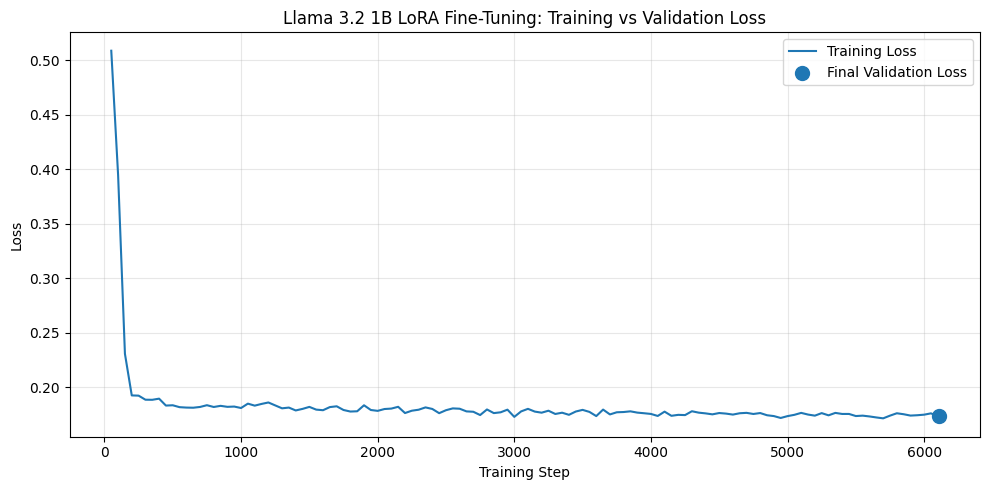

In [112]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    loss_df["Step"],
    loss_df["Training Loss"],
    label="Training Loss"
)

plt.scatter(
    6106,
    0.173505,
    s=100,
    label="Final Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Llama 3.2 1B LoRA Fine-Tuning: Training vs Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()